#**PRACTICA 1**
**Análisis Exploratorio de Datos (EDA)**

#Carga y descripción
1. Carga el fichero y muestra shape, head() y info().

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df= pd.read_csv('/content/Telco-Customer-Churn.csv')

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
df.shape


(7043, 21)

In [ ]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


2. ¿Qué variables son numéricas y cuáles categóricas? ¿Alguna numérica está codificada como
texto? (Pista: revisa TotalCharges.)


**Numéricas:** SeniorCitizen, tenure y MonthlyCharges.

**Categóricas:** el resto

**TotalCharges debería de ser numérica pero es categórica, se lee como object por las celdas que contienen solo espacio en blanco.**

3. Comprueba si hay identificadores que no aportan información al modelo

Como el atributo customerID tiene 7043 filas son todos un valor diferente y no añade información.

In [ ]:
df.nunique()

,0
customerID,7043
gender,2
SeniorCitizen,2
Partner,2
Dependents,2
tenure,73
PhoneService,2
MultipleLines,3
InternetService,3
OnlineSecurity,3


In [ ]:
print(df.groupby("gender")["Churn"].value_counts(normalize=True))
print(df.groupby("PhoneService")["Churn"].value_counts(normalize=True))

gender  Churn
Female  No       0.730791
        Yes      0.269209
Male    No       0.738397
        Yes      0.261603
Name: proportion, dtype: float64
PhoneService  Churn
No            No       0.750733
              Yes      0.249267
Yes           No       0.732904
              Yes      0.267096
Name: proportion, dtype: float64


Las variables gender y PhoneService no  tienen relación con churn, porque encontramos casi el mismo porcentaje de clientes que abandonaron la empresa en hombres y en mujeres, al igual que los que tienen servicio telefónico y no lo tienen.

In [ ]:
print(df.groupby("StreamingTV")["Churn"].value_counts(normalize=True))
print(df.groupby("StreamingMovies")["Churn"].value_counts(normalize=True))

StreamingTV          Churn
No                   No       0.664769
                     Yes      0.335231
No internet service  No       0.925950
                     Yes      0.074050
Yes                  No       0.699298
                     Yes      0.300702
Name: proportion, dtype: float64
StreamingMovies      Churn
No                   No       0.663196
                     Yes      0.336804
No internet service  No       0.925950
                     Yes      0.074050
Yes                  No       0.700586
                     Yes      0.299414
Name: proportion, dtype: float64


StremingTV y StreamingMovies coinciden en valores asi q podríamos eliminar una de las 2.

In [ ]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
(df["tenure"] * df["MonthlyCharges"]).corr(df["TotalCharges"])

np.float64(0.9995598572867936)

Se puede calcular TotalCharges con MonthlyCharges por los meses que lleva el cliente(ternure), por lo que se podría eliminar la columna de TotalCharges.

In [ ]:
print(df["MultipleLines"].value_counts())
print(df["PhoneService"].value_counts())

MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64
PhoneService
Yes    6361
No      682
Name: count, dtype: int64


Desde MultipleLines se puede averiguar los valores de PhoneService, por lo que esta columna se puede eliminar.

#Calidad de los datos
4. Localiza y cuantifica los valores ausentes. ¿En qué variable están y qué porcentaje representan? Propón al menos dos estrategias de tratamiento.

isna() devuelve 0, porque los huecos son espacios en blanco, pero hay 11 clientes que tienen la columna TotalCharges vacía.


In [ ]:
for columna in df.select_dtypes('object'):
  print(df[columna].value_counts(dropna=False))

customerID
3186-AJIEK    1
7590-VHVEG    1
5575-GNVDE    1
8775-CEBBJ    1
2823-LKABH    1
             ..
6713-OKOMC    1
1452-KIOVK    1
9305-CDSKC    1
9237-HQITU    1
7795-CFOCW    1
Name: count, Length: 7043, dtype: int64
gender
Male      3555
Female    3488
Name: count, dtype: int64
Partner
No     3641
Yes    3402
Name: count, dtype: int64
Dependents
No     4933
Yes    2110
Name: count, dtype: int64
PhoneService
Yes    6361
No      682
Name: count, dtype: int64
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64
OnlineBackup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dtype: int64
DeviceProtection
No                     3095
Yes               

In [ ]:
df[df["TotalCharges"].isna()][["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


Como observamos, aquellas columnas con TotalCharges vacías son aquellas que llevan 0 meses de antigüedad. Como soluciones, podemos rellenar los huecos en TotalCharges con 0, debido a que al llevar 0 meses el total Pagado es 0, o eliminar esos clientes siendo un 0,16% de los datos.

5. ¿Existen filas duplicadas? Justifica.

In [ ]:
df.duplicated().sum()

np.int64(0)

6. Comprueba si el problema está desbalanceado. Calcula la proporción de cada clase y
comenta las implicaciones para el modelado.


Churn
No     5174
Yes    1869
Name: count, dtype: int64


<Axes: xlabel='Churn', ylabel='count'>

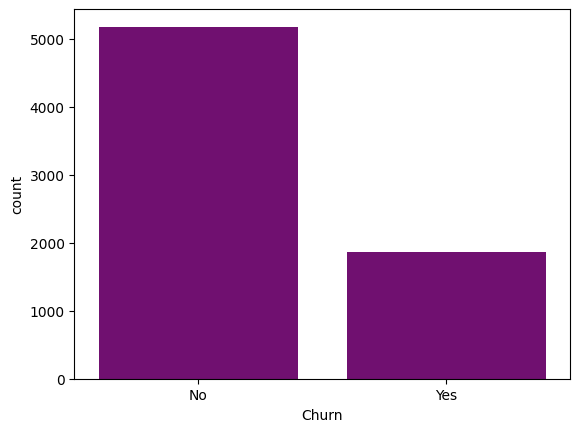

In [ ]:
print(df['Churn'].value_counts())
sns.countplot(data=df, x="Churn", color="purple")


El problema está desbalanceado, 5174 no abandonan, frente a 1869 que sí.

#3. Análisis univariante
7. Representa la distribución de MonthlyCharges, tenure y TotalCharges (histogramas y
diagramas de caja).

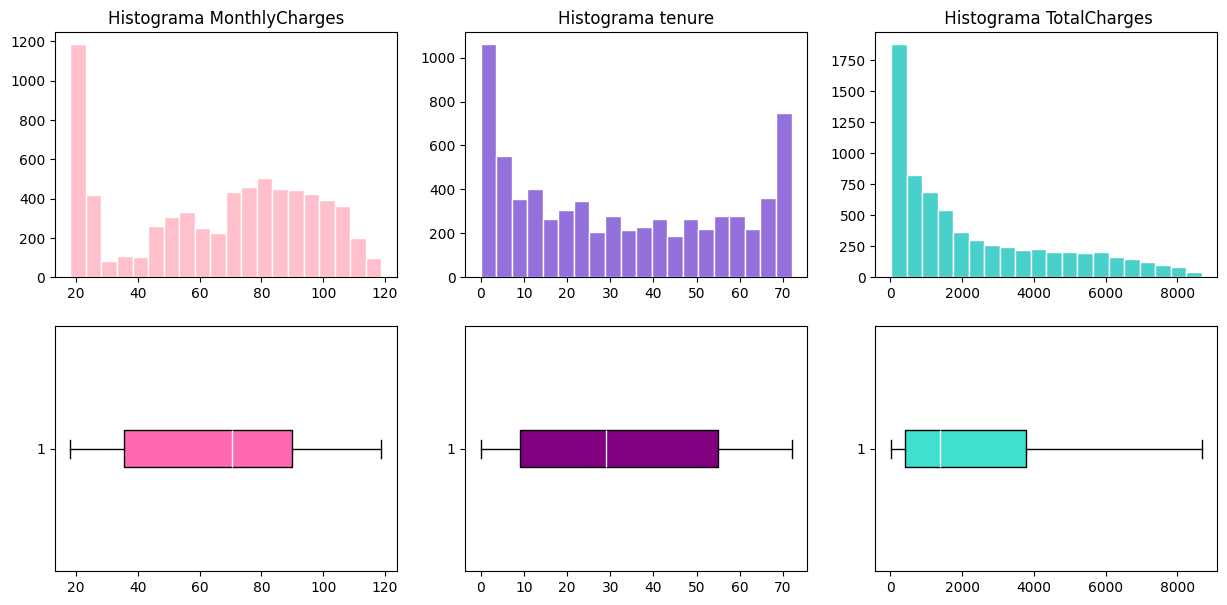

In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
ax[0,0].hist(df["MonthlyCharges"], bins=20, color="pink", edgecolor="white")
ax[0,0].set_title("Histograma MonthlyCharges")

ax[0,1].hist(df["tenure"], bins=20, color="mediumpurple", edgecolor="white")
ax[0,1].set_title("Histograma tenure")

ax[0,2].hist(df["TotalCharges"], bins=20, color="mediumturquoise", edgecolor="white")
ax[0,2].set_title(" Histograma TotalCharges")

ax[1,0].boxplot(df["MonthlyCharges"], vert=False, patch_artist=True, boxprops=dict(facecolor="hotpink"), medianprops=dict(color="white"))
ax[1,1].boxplot(df["tenure"], vert=False, patch_artist=True, boxprops=dict(facecolor="purple"), medianprops=dict(color="white"))
ax[1,2].boxplot(df["TotalCharges"].dropna(), vert=False, patch_artist=True, boxprops=dict(facecolor="turquoise"), medianprops=dict(color="white"))
plt.show()

In [ ]:
df[["MonthlyCharges", "tenure", "TotalCharges"]].describe().round(2)

,MonthlyCharges,tenure,TotalCharges
count,7043.00,7043.00,7032.00
mean,64.76,32.37,2283.30
std,30.09,24.56,2266.77
min,18.25,0.00,18.80
25%,35.50,9.00,401.45
50%,70.35,29.00,1397.48
75%,89.85,55.00,3794.74
max,118.75,72.00,8684.80


8. Representa la frecuencia de Contract, InternetService y PaymentMethod


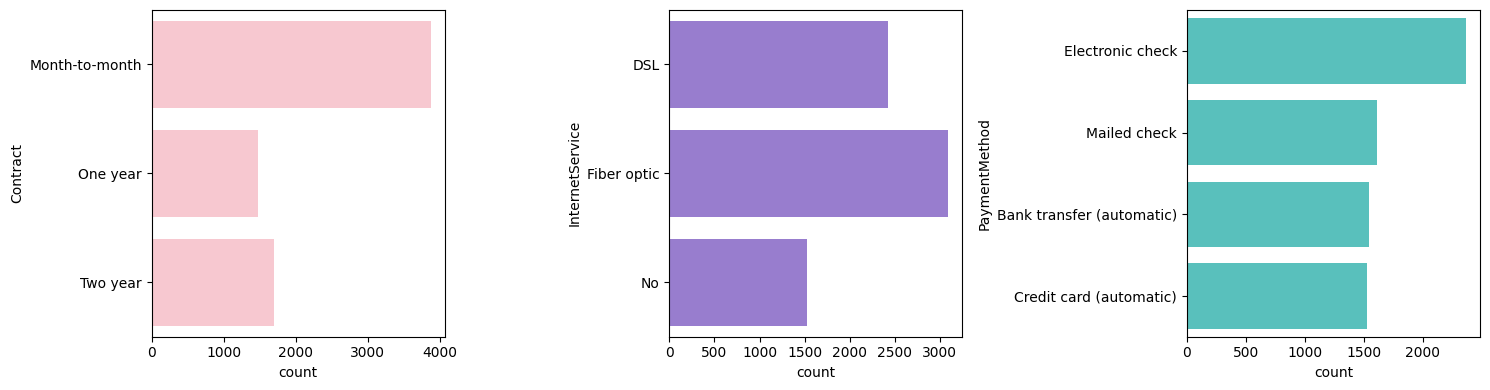

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

sns.countplot(data=df, y="Contract", color="pink", ax=ax[0])
sns.countplot(data=df, y="InternetService", color="mediumpurple", ax=ax[1])
sns.countplot(data=df, y="PaymentMethod", color="mediumturquoise", ax=ax[2])

plt.tight_layout()
plt.show()

9. ¿Qué variables presentan asimetría? ¿Detectas valores atípicos? Razona si son errores o
clientes legítimos.


In [ ]:
df[["MonthlyCharges", "tenure", "TotalCharges"]].skew()
#Skew permite ver la asimetría

,0
MonthlyCharges,-0.220524
tenure,0.239540
TotalCharges,0.961642


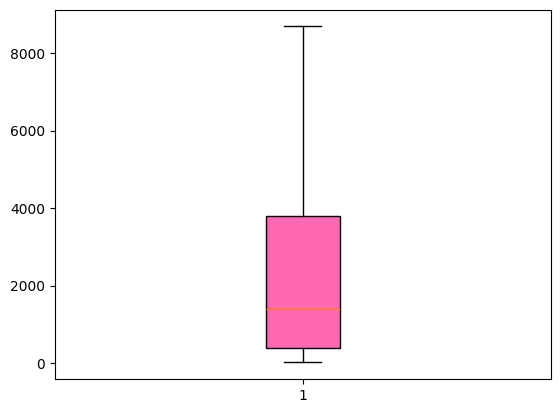

In [ ]:
from typing import Dict

plt.boxplot(df["TotalCharges"].dropna(), patch_artist=True,boxprops=dict(facecolor="hotpink"))
plt.show()

Como hemos observado en los diagramas anteriores la variable que presenta asimetría es TotalCharges, sin embargo, no se encuentra ningún valor atípico

#4. Análisis multivariante
10. Calcula la matriz de correlación de las variables numéricas y represéntala con un mapa de
calor. ¿Qué relación observas entre TotalCharges, tenure y MonthlyCharges?.

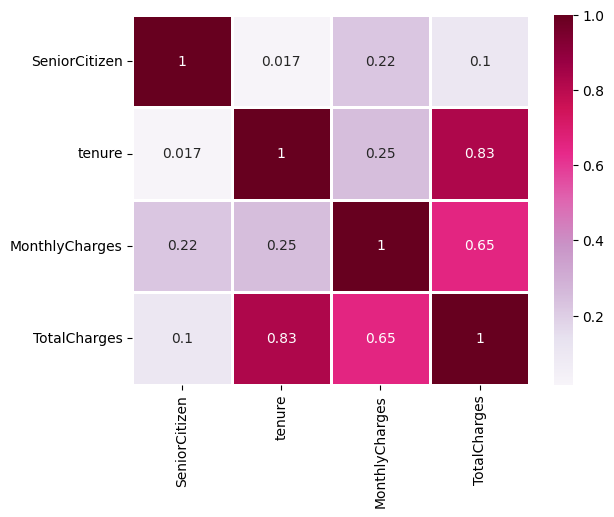

In [ ]:
ndf = df.select_dtypes(["number"])
corr = ndf.corr()
sns.heatmap(corr, annot=True, cmap="PuRd",linewidths=2, linecolor="white")
plt.show()

TotalCharges tiene una gran correlación con tenure, es decir, q los que llevan más tiempo, son los que más dinero han pagado,  al igual que con MonthlyCharges tiene una relación moderada(0,65),los que más dinero pagan al mes suelen ser los que más dinero acumulen. Sin embargo, tenure y MonthlyChanges tiene una correlación baja, ya que no influye mucho los meses que lleves en la empresa con el dinero mensual a pagar. Finalmente SeniorCritizen es una correlación débil con el resto de variables, porque no influye la edad.

11. Analiza cómo varía la tasa de Churn según Contract, InternetService y tenure (agrupa
tenure en tramos). Escribe al menos tres reglas del tipo «si A es X entonces el cliente
tiende a abandonar».


Contract
Month-to-month    0.427097
One year          0.112695
Two year          0.028319
Name: abandona, dtype: float64
InternetService
DSL            0.189591
Fiber optic    0.418928
No             0.074050
Name: abandona, dtype: float64
tramo_tenure
(-0.001, 9.0]    0.497843
(9.0, 29.0]      0.283382
(29.0, 55.0]     0.188482
(55.0, 72.0]     0.077493
Name: abandona, dtype: float64


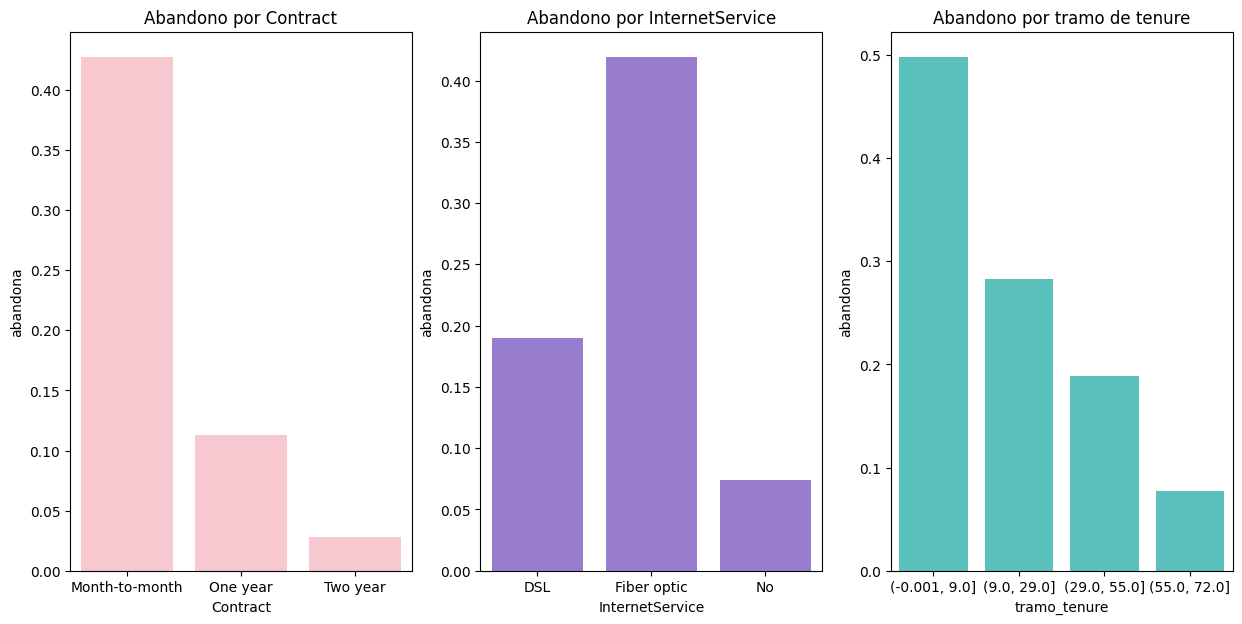

In [ ]:
df["abandona"] = df["Churn"].map({"No": 0, "Yes": 1})

df["tramo_tenure"] = pd.qcut(df["tenure"], 4)

print(df.groupby("Contract")["abandona"].mean())
print(df.groupby("InternetService")["abandona"].mean())
print(df.groupby("tramo_tenure", observed=True)["abandona"].mean())

plt.figure(figsize=[15, 7])

plt.subplot(1, 3, 1)
sns.barplot(data=df, x="Contract", y="abandona", errorbar=None, color="pink")
plt.title("Abandono por Contract")

plt.subplot(1, 3, 2)
sns.barplot(data=df, x="InternetService", y="abandona", errorbar=None, color="mediumpurple")
plt.title("Abandono por InternetService")

plt.subplot(1, 3, 3)
sns.barplot(data=df, x="tramo_tenure", y="abandona", errorbar=None, color="mediumturquoise")
plt.title("Abandono por tramo de tenure")

plt.show()

Si el contrato es mes a mes, el cliente suele abandonar.
Si el cliente tiene fibra óptica tiende a abandonar.
Si el cliente lleva más de 55 meses, suele permanecer en la empresa

12. ¿Qué combinación de dos o tres variables separa mejor a los clientes que abandonan?


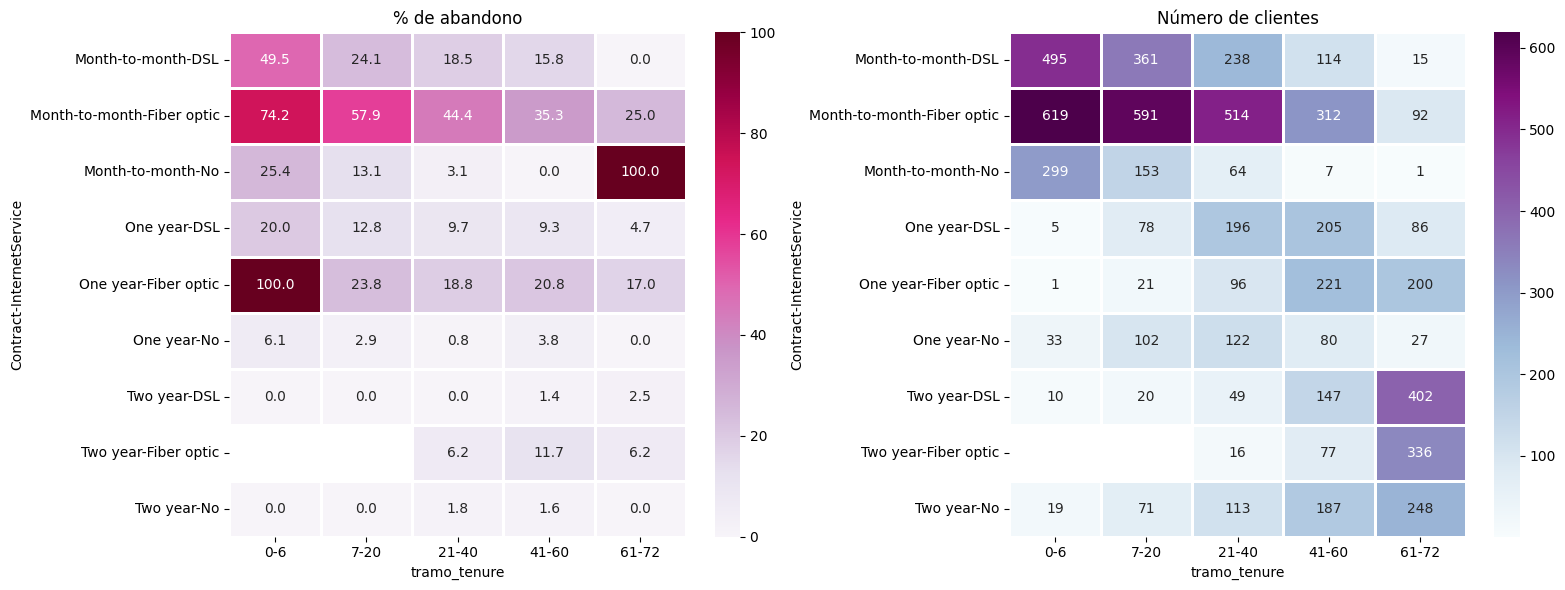

In [ ]:
df["tramo_tenure"] = pd.qcut(df["tenure"], 5, labels=["0-6", "7-20", "21-40", "41-60", "61-72"])
tabla = df.pivot_table(index=["Contract", "InternetService"], columns="tramo_tenure", values="abandona", aggfunc="mean", observed=True) * 100
tabla1 = df.pivot_table(index=["Contract", "InternetService"], columns="tramo_tenure", values="abandona", aggfunc="count", observed=True)

plt.figure(figsize=[16, 6])

plt.subplot(1, 2, 1)
sns.heatmap(tabla, annot=True, fmt=".1f", cmap="PuRd", linewidths=2, linecolor="white")
plt.title("% de abandono")

plt.subplot(1, 2, 2)
sns.heatmap(tabla1, annot=True, fmt=".0f", cmap="BuPu", linewidths=2, linecolor="white")
plt.title("Número de clientes")

plt.tight_layout()
plt.show()

  Así podemos observar bien que el mayor riesgo lo tienen los clientes con contrato mes a mes, con fibra óptica, y en los primeros 6 o 7 meses, porque tiene la tasa más alta de abandono, por lo que las variables que separan mejor los clientes que abandonan, son los del ejercicio anterior.

#5. CONCLUSIONES
13. Resume en cinco viñetas los hallazgos principales

1. El problema está desbalanceado, de 7043 clientes el 73,5% no abandonan y el 25,6% si que lo hace.
2. Hay variables que son casi identicas o con redundancia, por lo que podrían eliminarse.
3. Las personas con contrato mes a mes, los que tienen fibra óptica o los que llevan menos de 9 meses son los que más riesgo a abandonar tienen.
4. TotalCharges es una variable asimétrica, porque los que más tiempo llevas son los que más han pagado. Y aunque no hay clientes duplicados, hay 11 valores vacíos en TotalCharges que se debería de tratar.
5. Y como vemos abajo, podemos observar también que los clientes que más abandonan son los que pagan con electronic check. los que no tienen TechSupport o OnlineSecurity abandonan más frente a los que sí tienen.

In [ ]:
print((df.groupby("PaymentMethod")["abandona"].mean() * 100).round(1))
print((df.groupby("TechSupport")["abandona"].mean() * 100).round(1))
print((df.groupby("OnlineSecurity")["abandona"].mean() * 100).round(1))

PaymentMethod
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2
Electronic check             45.3
Mailed check                 19.1
Name: abandona, dtype: float64
TechSupport
No                     41.6
No internet service     7.4
Yes                    15.2
Name: abandona, dtype: float64
OnlineSecurity
No                     41.8
No internet service     7.4
Yes                    14.6
Name: abandona, dtype: float64


14. Formula una recomendación de negocio concreta orientada a reducir el abandono

Hay que realizar una retención de los clientes nuevos, con contrato mes a mes y además con fibra óptica, por lo visto anteriormente.
Algunas medidas son:
1. Revisar si hay algún problema en
la fibra óptica.
2. Incentivarlos a pasar al contrato anual o de 2 años, con algún descuento o mes gratis.
3. Promover el pago automático frente al cheque electrónico donde los clientes deben introducir los datos todos los meses.
4. Proporcionar o regalar soporte técnico o seguridad online.